# 02 Exploratory analysis
**Goal:** find the daily, weekly and yearly patterns, the temperature-load relationship and the autocorrelation structure, and turn each plot into a modelling decision.

**Input:** `data/processed/hourly.csv`  **Output:** figures in `reports/figures/`

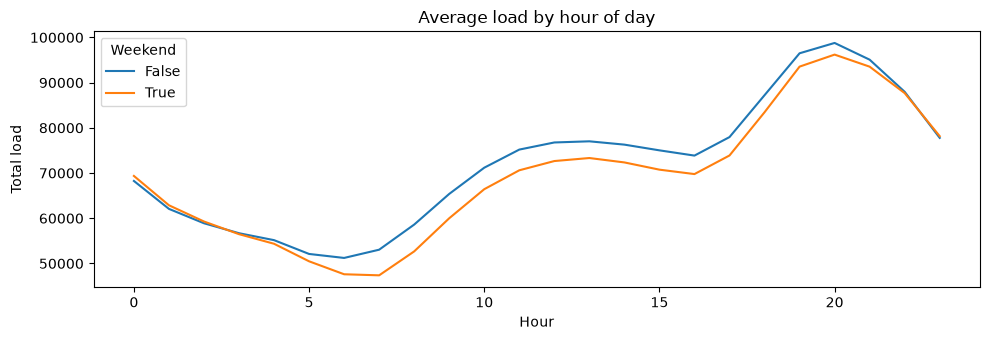

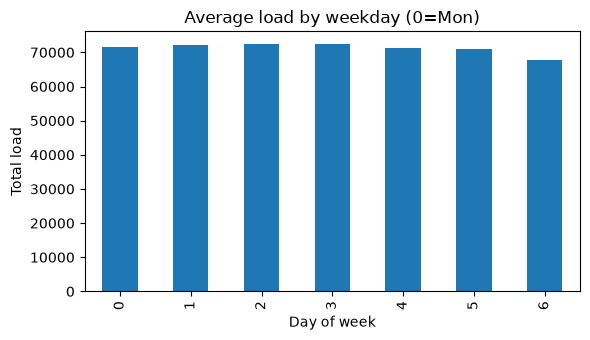

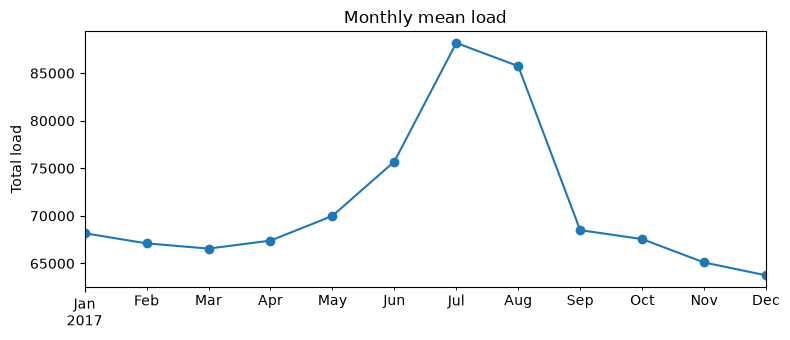

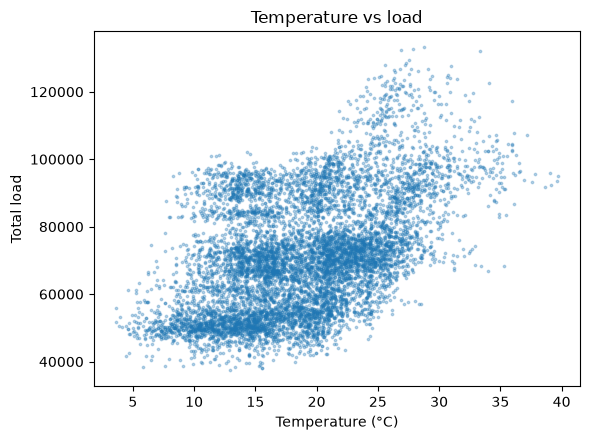

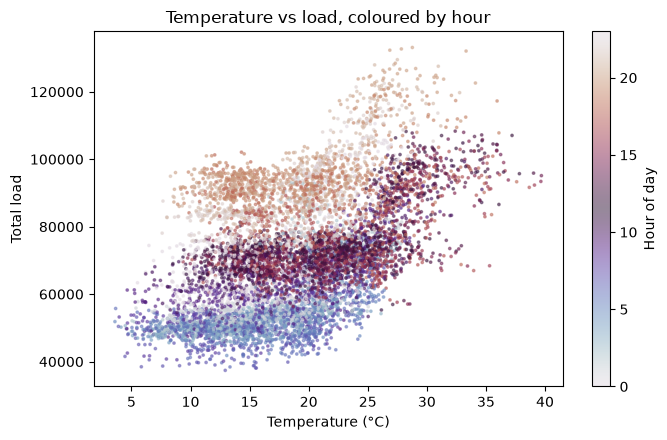

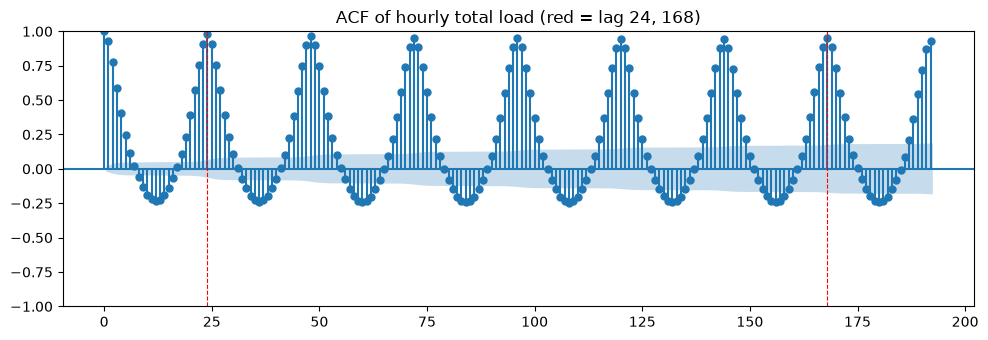

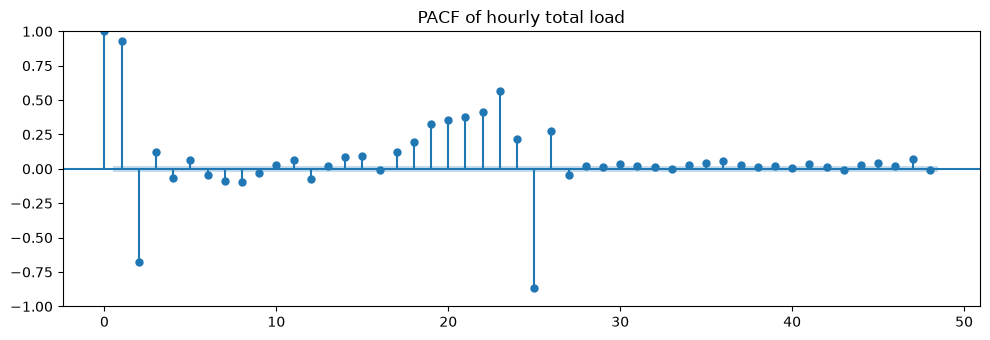

1      0.931
24     0.980
48     0.970
144    0.958
168    0.966
192    0.950
Name: autocorr, dtype: float64


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

h = pd.read_csv("../data/processed/hourly.csv", index_col=0, parse_dates=True)
h["hour"] = h.index.hour
h["dow"] = h.index.day_of_week
h["weekend"] = h["dow"] >= 5

def finish(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

# --- 1. Daily shape: hour of day, weekday vs weekend
fig, ax = plt.subplots(figsize=(10, 3.5))
h.groupby(["hour", "weekend"])["total"].mean().unstack().plot(ax=ax)
ax.set(title="Average load by hour of day", xlabel="Hour", ylabel="Total load")
ax.legend(title="Weekend")
finish("01_daily_shape")

# --- 2. Weekly shape: day of week
fig, ax = plt.subplots(figsize=(6, 3.5))
h.groupby("dow")["total"].mean().plot(kind="bar", ax=ax)
ax.set(title="Average load by weekday (0=Mon)", xlabel="Day of week", ylabel="Total load")
finish("02_weekly_shape")

# --- 3. Yearly shape: monthly mean (one year only!)
fig, ax = plt.subplots(figsize=(8, 3.5))
h["total"].resample("MS").mean().plot(ax=ax, marker="o")
ax.set(title="Monthly mean load", xlabel="", ylabel="Total load")
finish("03_monthly_trend")

# --- 4a. Temperature vs load (raw)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(h["Temperature"], h["total"], s=3, alpha=.3)
ax.set(title="Temperature vs load", xlabel="Temperature (°C)", ylabel="Total load")
finish("04a_temp_scatter")

# --- 4b. Same scatter, coloured by hour (tests the hidden-variable idea)
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(h["Temperature"], h["total"], c=h["hour"], cmap="twilight", s=3, alpha=.5)
plt.colorbar(sc, ax=ax, label="Hour of day")
ax.set(title="Temperature vs load, coloured by hour", xlabel="Temperature (°C)", ylabel="Total load")
finish("04b_temp_scatter_by_hour")

# --- 5a. ACF over 8 days, with daily and weekly lags marked
fig, ax = plt.subplots(figsize=(10, 3.5))
plot_acf(h["total"], lags=24 * 8, ax=ax)
for lag in (24, 168):
    ax.axvline(lag, color="red", ls="--", lw=.8)
ax.set_title("ACF of hourly total load (red = lag 24, 168)")
finish("05a_acf")

# --- 5b. PACF
fig, ax = plt.subplots(figsize=(10, 3.5))
plot_pacf(h["total"], lags=48, method="ywm", ax=ax)
ax.set_title("PACF of hourly total load")
finish("05b_pacf")

# --- 6. Numbers behind the ACF, so you don't just eyeball the plot
acf_vals = pd.Series([h["total"].autocorr(lag=l) for l in (1, 24, 48, 144, 168, 192)],
                     index=[1, 24, 48, 144, 168, 192], name="autocorr")
print(acf_vals.round(3))

## Conclusion (plot → decision)
| Plot | Finding | Decision |
|---|---|---|
| Daily shape | trough about 5 am, midday plateau, peak about 8 pm; weekends lower in the daytime | hour as sin/cos, weekend flag |
| Weekly shape | Sunday about 5% lower than midweek (the bar chart axis starts at 0, which hides this) | weekend flag is enough |
| Monthly | peak in July-August, sharp drop in September, only one year | do not use month or day-of-year features |
| Temperature scatter | not linear; bands are hours of the day | non-linear model, hour matters more than temperature |
| ACF / PACF | peaks at every multiple of 24; lag 1 is huge | with a midnight forecast origin, only lags of 24 h or more are usable |

Autocorrelation: lag 24 = 0.980, lag 168 = 0.966 (above lags 144 = 0.958 and 192 = 0.950), so there is a weak weekly effect.